# Human Activity Recognition: Data Check and Baseline Models

**AAI 501, University of San Diego** | Francois Lubin, Lernik Avetisyan, Alex Denbaugh

This notebook covers the first stage of the project:

1. Load the UCI HAR dataset (Reyes-Ortiz et al., 2013) with feature names and activity labels.
2. Verify it matches the proposal: 10,299 windows, 30 volunteers, 561 features, 6 activities, no missing values.
3. Train the five classifiers from the proposal on the volunteer-wise train/test split and compare them.

**Data location.** Put the extracted `UCI HAR Dataset` folder in a `data/` folder next to this notebook.
The data is not stored in the repository (see `README.md` for the download link).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
DATA_DIR = Path("data") / "UCI HAR Dataset"
assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR.resolve()}"

## 1. Load the data

`features.txt` lists 561 features but only 477 distinct names: some frequency-band features
(the `bandsEnergy` group) share a name. We append the feature's index to every name so each
column is unique.

In [2]:
def load_feature_names(data_dir):
    """Return 561 unique feature names, each suffixed with its index."""
    feats = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None,
                        names=["idx", "name"])
    return [f"{name}__{idx}" for idx, name in zip(feats["idx"], feats["name"])]


def load_activity_labels(data_dir):
    """Return a dict mapping label id (1-6) to activity name."""
    acts = pd.read_csv(data_dir / "activity_labels.txt", sep=r"\s+", header=None,
                       names=["id", "activity"])
    return dict(zip(acts["id"], acts["activity"]))


def load_split(data_dir, split, feature_names):
    """Load features X, label ids y, and volunteer ids for 'train' or 'test'."""
    folder = data_dir / split
    X = pd.read_csv(folder / f"X_{split}.txt", sep=r"\s+", header=None,
                    names=feature_names)
    y = pd.read_csv(folder / f"y_{split}.txt", header=None).iloc[:, 0]
    subject = pd.read_csv(folder / f"subject_{split}.txt", header=None).iloc[:, 0]
    return X, y.rename("label"), subject.rename("subject")


feature_names = load_feature_names(DATA_DIR)
activity_map = load_activity_labels(DATA_DIR)
class_names = [activity_map[i] for i in sorted(activity_map)]
short_names = ["Walk", "Up", "Down", "Sit", "Stand", "Lay"]  # for plots (Up/Down = stairs)

X_train, y_train, subj_train = load_split(DATA_DIR, "train", feature_names)
X_test, y_test, subj_test = load_split(DATA_DIR, "test", feature_names)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (7352, 561)  Test: (2947, 561)


## 2. Verify the data against the proposal

In [3]:
checks = {
    "Total windows (expect 10,299)": len(X_train) + len(X_test),
    "Features (expect 561)": X_train.shape[1],
    "Volunteers (expect 30)": pd.concat([subj_train, subj_test]).nunique(),
    "Train volunteers": subj_train.nunique(),
    "Test volunteers": subj_test.nunique(),
    "Volunteers in both splits (expect 0)": len(set(subj_train) & set(subj_test)),
    "Missing values (expect 0)": int(X_train.isna().sum().sum() + X_test.isna().sum().sum()),
    "Activities (expect 6)": pd.concat([y_train, y_test]).nunique(),
    "Feature value range": f"[{X_train.values.min():.1f}, {X_train.values.max():.1f}]",
}
pd.Series(checks, name="value").to_frame()

,value
"Total windows (expect 10,299)",10299
Features (expect 561),561
Volunteers (expect 30),30
Train volunteers,21
Test volunteers,9
Volunteers in both splits (expect 0),0
Missing values (expect 0),0
Activities (expect 6),6
Feature value range,"[-1.0, 1.0]"


The provided split already keeps each volunteer entirely in training (21 people) or testing
(9 people), which is what the proposal requires for testing generalization to new people.
Features are pre-scaled to [-1, 1].

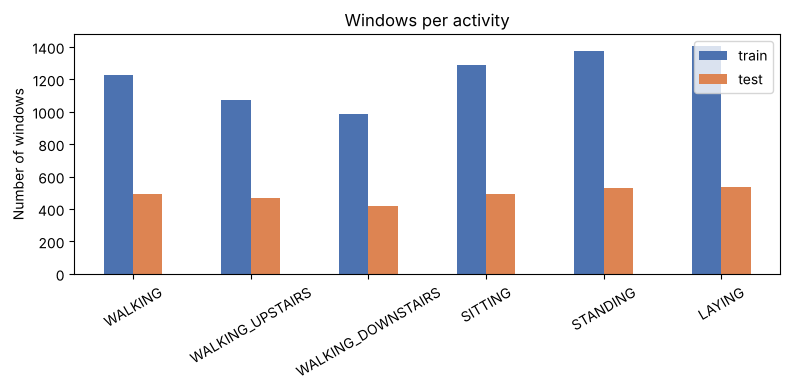

,train,test
label,,
WALKING,1226,496
WALKING_UPSTAIRS,1073,471
WALKING_DOWNSTAIRS,986,420
SITTING,1286,491
STANDING,1374,532
LAYING,1407,537


In [4]:
counts = pd.DataFrame({
    "train": y_train.map(activity_map).value_counts(),
    "test": y_test.map(activity_map).value_counts(),
}).loc[class_names]

ax = counts.plot.bar(figsize=(8, 4), rot=30, color=["#4C72B0", "#DD8452"])
ax.set_title("Windows per activity")
ax.set_ylabel("Number of windows")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
counts

The classes are reasonably balanced, so accuracy is a fair headline metric; we also report macro F1.

## 3. Baseline classifiers

All five models use default or near-default settings; tuning comes later with volunteer-wise
cross-validation. Logistic regression, k-NN, and SVM are wrapped with a `StandardScaler`
because they are sensitive to feature scale. For gradient boosting we use scikit-learn's
`HistGradientBoostingClassifier`, which is much faster than `GradientBoostingClassifier`
on 561 features.

In [5]:
models = {
    "Logistic regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "k-nearest neighbors": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF kernel)": make_pipeline(
        StandardScaler(), SVC(kernel="rbf", random_state=RANDOM_STATE)),
    "Random forest": RandomForestClassifier(
        n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

results, predictions = [], {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Train time (s)": fit_seconds,
    })
    print(f"{name:22s} accuracy={results[-1]['Accuracy']:.4f}  ({fit_seconds:.1f}s)")

results_df = (pd.DataFrame(results).set_index("Model")
              .sort_values("Accuracy", ascending=False))
results_df.style.format({"Accuracy": "{:.4f}", "Macro F1": "{:.4f}",
                         "Train time (s)": "{:.1f}"})

Logistic regression    accuracy=0.9552  (0.9s)


k-nearest neighbors    accuracy=0.8802  (0.1s)


SVM (RBF kernel)       accuracy=0.9522  (1.7s)


Random forest          accuracy=0.9287  (9.9s)


Gradient boosting      accuracy=0.9315  (11.6s)


,Accuracy,Macro F1,Train time (s)
Model,,,
Logistic regression,0.9552,0.9551,0.9
SVM (RBF kernel),0.9522,0.9515,1.7
Gradient boosting,0.9315,0.9309,11.6
Random forest,0.9287,0.9271,9.9
k-nearest neighbors,0.8802,0.8766,0.1


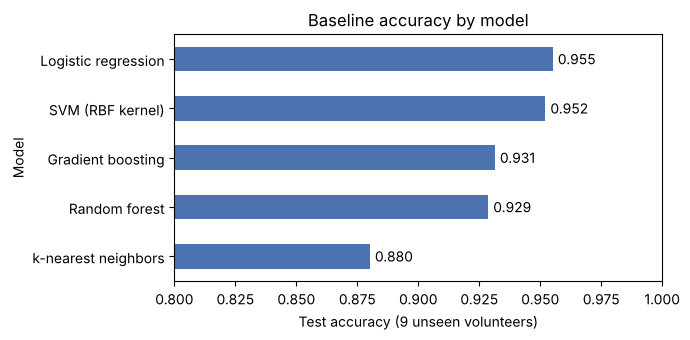

In [6]:
ax = results_df["Accuracy"].sort_values().plot.barh(figsize=(7, 3.5), color="#4C72B0")
ax.set_xlim(0.8, 1.0)
ax.set_xlabel("Test accuracy (9 unseen volunteers)")
ax.set_title("Baseline accuracy by model")
for i, v in enumerate(results_df["Accuracy"].sort_values()):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center")
plt.tight_layout()
plt.show()

## 4. Which activities get confused?

The proposal expects most errors between sitting and standing. The confusion matrices below
show counts on the test set (rows are true activities, columns are predictions).

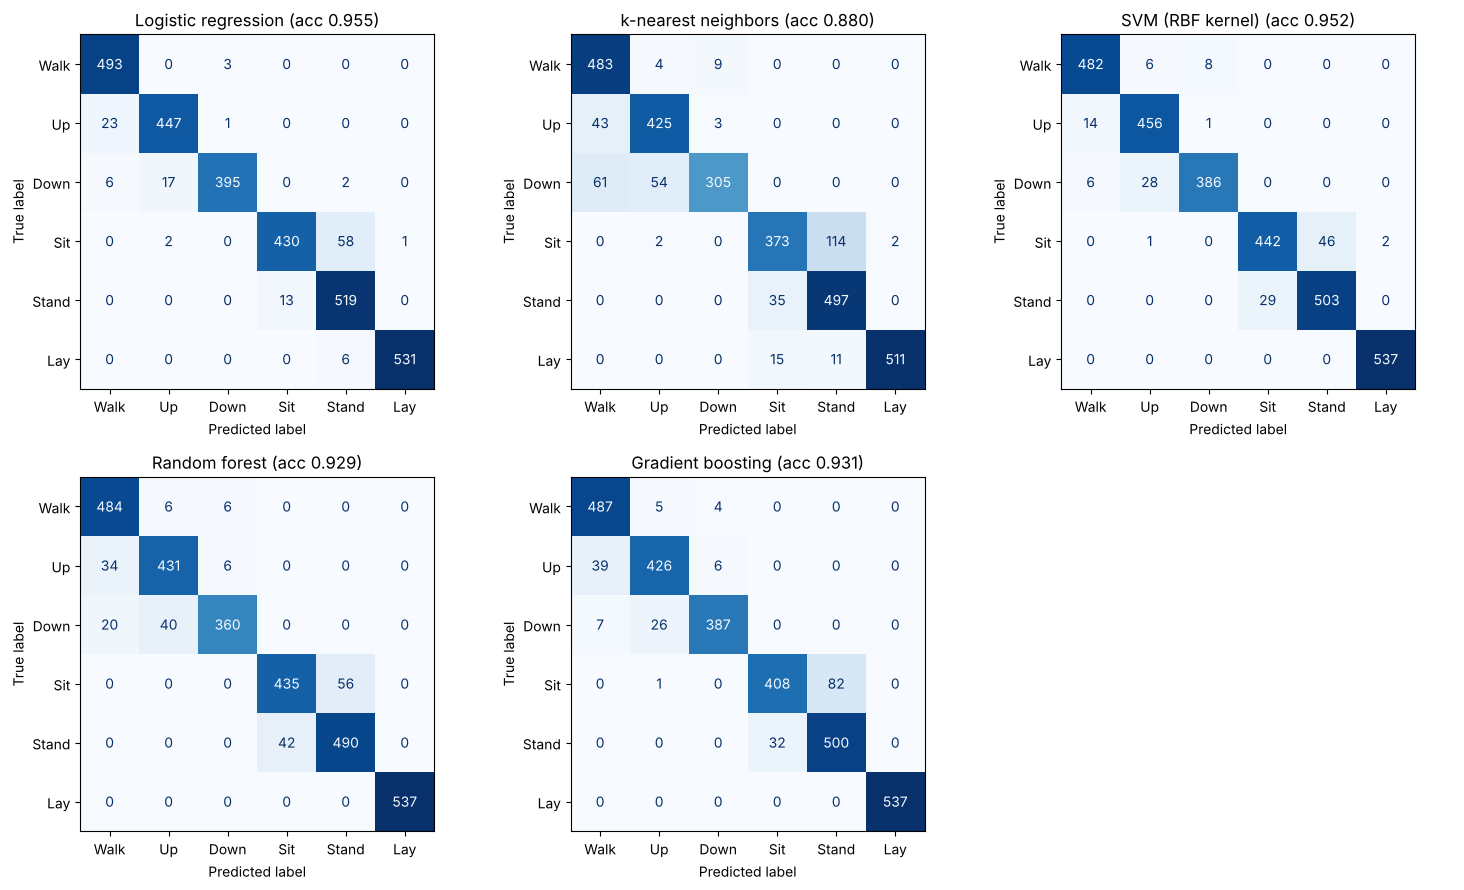

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=short_names).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (acc {accuracy_score(y_test, y_pred):.3f})")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [8]:
moving, still = {1, 2, 3}, {4, 5, 6}
rows = []
for name, y_pred in predictions.items():
    errors = y_test.values != y_pred
    sit_stand = errors & np.isin(y_test.values, [4, 5]) & np.isin(y_pred, [4, 5])
    cross = errors & (np.isin(y_test.values, list(moving)) != np.isin(y_pred, list(moving)))
    rows.append({
        "Model": name,
        "Total errors": int(errors.sum()),
        "Sitting <-> standing": int(sit_stand.sum()),
        "Share of errors": sit_stand.sum() / max(errors.sum(), 1),
        "Moving <-> still": int(cross.sum()),
    })
pd.DataFrame(rows).set_index("Model").style.format({"Share of errors": "{:.0%}"})

,Total errors,Sitting <-> standing,Share of errors,Moving <-> still
Model,,,,
Logistic regression,132,71,54%,4
k-nearest neighbors,353,149,42%,2
SVM (RBF kernel),141,75,53%,1
Random forest,210,98,47%,0
Gradient boosting,202,114,56%,1


Per-class detail for the best model:

In [9]:
best = results_df.index[0]
print(best)
print(classification_report(y_test, predictions[best], target_names=class_names, digits=3))

Logistic regression
                    precision    recall  f1-score   support

           WALKING      0.944     0.994     0.969       496
  WALKING_UPSTAIRS      0.959     0.949     0.954       471
WALKING_DOWNSTAIRS      0.990     0.940     0.965       420
           SITTING      0.971     0.876     0.921       491
          STANDING      0.887     0.976     0.929       532
            LAYING      0.998     0.989     0.993       537

          accuracy                          0.955      2947
         macro avg      0.958     0.954     0.955      2947
      weighted avg      0.957     0.955     0.955      2947



## 5. Takeaways and next steps

- **Logistic regression (95.5%) and the RBF SVM (95.2%) lead**, and they also train in under
  2 seconds. Gradient boosting (93.1%) and random forest (92.9%) follow; k-NN is last (88.0%).
- **Moving vs. still is essentially solved**: at most 4 of 2,947 test windows cross that line
  for any model.
- **Sitting vs. standing is the largest single source of error** for every model (42-56% of
  errors), as the proposal predicted (Anguita et al., 2013). Logistic regression mostly
  mislabels sitting as standing (58 windows).
- **A second error pattern the proposal did not mention**: the three walking activities get
  mixed up, especially by the tree models and k-NN (for example, k-NN labels 115 downstairs
  windows as walking or upstairs). This is worth a sentence in the report.
- These are untuned baselines on 9 unseen volunteers, so they measure generalization to new
  people.

**Next notebooks**

1. Tune the strongest models with `GroupKFold` on the training volunteers (issue a).
2. Rank features by random forest importance and plot accuracy vs. number of features (issue c).
3. PCA, then k-means and hierarchical clustering; test whether cluster distances help a
   classifier (issue d).